In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

RANDOM_STATE = 42
CLASS_ORDER = ["Low", "Medium", "High"]
print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
df = pd.read_csv("../data/raw/synthetic_atm_data.csv", parse_dates=["date"])
df = df.sort_values(["date", "zone_id"]).reset_index(drop=True)

# Recreate these columns because the raw CSV does not contain notebook-only changes.
df["withdrawals_per_atm"] = df["withdrawal_count"] / df["atm_count"].replace(0, np.nan)
df["unusual_activity_ratio"] = (
    df["unusual_activity_count"] / df["withdrawal_count"].replace(0, np.nan)
)
df["avg_daily_incidents_30d"] = df["incidents_sum_30d"] / 30
df["withdrawal_amount_per_atm"] = (
    df["total_withdrawal_amount"] / df["atm_count"].replace(0, np.nan)
)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
display(df.head())


Dataset shape: (6036, 25)
Date range: 2025-01-31 to 2026-06-17


,zone_id,date,latitude,longitude,day_of_week,month,is_weekend,atm_count,withdrawal_count,avg_withdrawal_amount,...,incidents_sum_7d,withdrawals_sum_30d,unusual_activity_sum_30d,incidents_sum_30d,target_incidents_next_7d,target_risk,withdrawals_per_atm,unusual_activity_ratio,avg_daily_incidents_30d,withdrawal_amount_per_atm
0,ZONE_01,2025-01-31,31.000914,75.000198,4,1,0,9,121,1953.02,...,4.0,2816.0,42.0,10.0,2,Medium,13.444444,0.024793,0.333333,26257.272222
1,ZONE_02,2025-01-31,30.996880,75.028382,4,1,0,8,62,3243.63,...,3.0,2067.0,60.0,13.0,4,High,7.750000,0.064516,0.433333,25138.116250
2,ZONE_03,2025-01-31,31.002251,75.051403,4,1,0,11,89,3107.39,...,0.0,2374.0,57.0,9.0,5,High,8.090909,0.011236,0.300000,25141.588182
3,ZONE_04,2025-01-31,31.002822,75.072422,4,1,0,12,80,2126.98,...,2.0,1763.0,57.0,10.0,3,Medium,6.666667,0.050000,0.333333,14179.835000
4,ZONE_05,2025-01-31,31.019147,75.001106,4,1,0,6,71,4218.00,...,3.0,1945.0,48.0,11.0,3,Medium,11.833333,0.014085,0.366667,49913.053333


In [3]:
FEATURES = [
    "zone_id", "latitude", "longitude", "day_of_week", "month", "is_weekend",
    "atm_count", "withdrawal_count", "avg_withdrawal_amount",
    "total_withdrawal_amount", "unusual_activity_count",
    "withdrawals_sum_7d", "unusual_activity_sum_7d", "incidents_sum_7d",
    "withdrawals_sum_30d", "unusual_activity_sum_30d", "incidents_sum_30d",
    "withdrawals_per_atm", "unusual_activity_ratio",
    "avg_daily_incidents_30d", "withdrawal_amount_per_atm"
]
TARGET = "target_risk"

X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(str).copy()

print("Number of predictors:", len(FEATURES))
display(y_all.value_counts().reindex(CLASS_ORDER).rename("records").to_frame())


Number of predictors: 21


,records
target_risk,
Low,1421
Medium,2457
High,2158


In [4]:
unique_dates = np.sort(df["date"].unique())
split_index = int(len(unique_dates) * 0.80)
test_start = pd.Timestamp(unique_dates[split_index])
train_end = test_start - pd.Timedelta(days=7)

train_mask = df["date"] < train_end
test_mask = df["date"] >= test_start

X_train, X_test = X_all.loc[train_mask].copy(), X_all.loc[test_mask].copy()
y_train, y_test = y_all.loc[train_mask].copy(), y_all.loc[test_mask].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", df.loc[train_mask, "date"].min().date(), "to",
      df.loc[train_mask, "date"].max().date())
print("Testing period:", df.loc[test_mask, "date"].min().date(), "to",
      df.loc[test_mask, "date"].max().date())

print("\nTraining classes:")
display(y_train.value_counts().reindex(CLASS_ORDER).rename("records").to_frame())
print("\nTesting classes:")
display(y_test.value_counts().reindex(CLASS_ORDER).rename("records").to_frame())

assert set(y_train.unique()) == set(CLASS_ORDER)
assert set(y_test.unique()) == set(CLASS_ORDER)


Training rows: 4740
Testing rows: 1212
Training period: 2025-01-31 to 2026-03-01
Testing period: 2026-03-09 to 2026-06-17

Training classes:


,records
target_risk,
Low,1092
Medium,1929
High,1719



Testing classes:


,records
target_risk,
Low,312
Medium,486
High,414


In [5]:
NUMERIC_FEATURES = [c for c in FEATURES if c != "zone_id"]
CATEGORICAL_FEATURES = ["zone_id"]

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
    ])

print("Preprocessor function ready.")


Preprocessor function ready.


In [6]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=10,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "SVM": SVC(
        C=1.0, kernel="rbf", probability=True,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=2,
        random_state=RANDOM_STATE
    )
}
print("Models:", list(models.keys()))


Models: ['Logistic Regression', 'KNN', 'Decision Tree', 'SVM', 'Random Forest', 'Gradient Boosting']


In [7]:
trained_models = {}
predictions = {}
results = []

for name, estimator in models.items():
    print("Training:", name)
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", estimator)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (OVR macro)": roc_auc_score(
            y_test, y_proba, labels=pipeline.named_steps["classifier"].classes_,
            multi_class="ovr", average="macro"
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "F1 (macro)", ascending=False
).reset_index(drop=True)
display(results_df.round(4))


Training: Logistic Regression
Training: KNN
Training: Decision Tree
Training: SVM
Training: Random Forest
Training: Gradient Boosting


,Model,Accuracy,Balanced Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OVR macro)
0,SVM,0.4158,0.4353,0.4180,0.4353,0.4079,0.3990,0.6070
1,Random Forest,0.4076,0.4108,0.4003,0.4108,0.3987,0.3984,0.6151
2,KNN,0.4101,0.3943,0.3967,0.3943,0.3939,0.4059,0.5850
3,Logistic Regression,0.4076,0.4430,0.4305,0.4430,0.3811,0.3624,0.6232
4,Gradient Boosting,0.4109,0.3794,0.4083,0.3794,0.3392,0.3648,0.6191
5,Decision Tree,0.3309,0.3465,0.3427,0.3465,0.3298,0.3267,0.5412


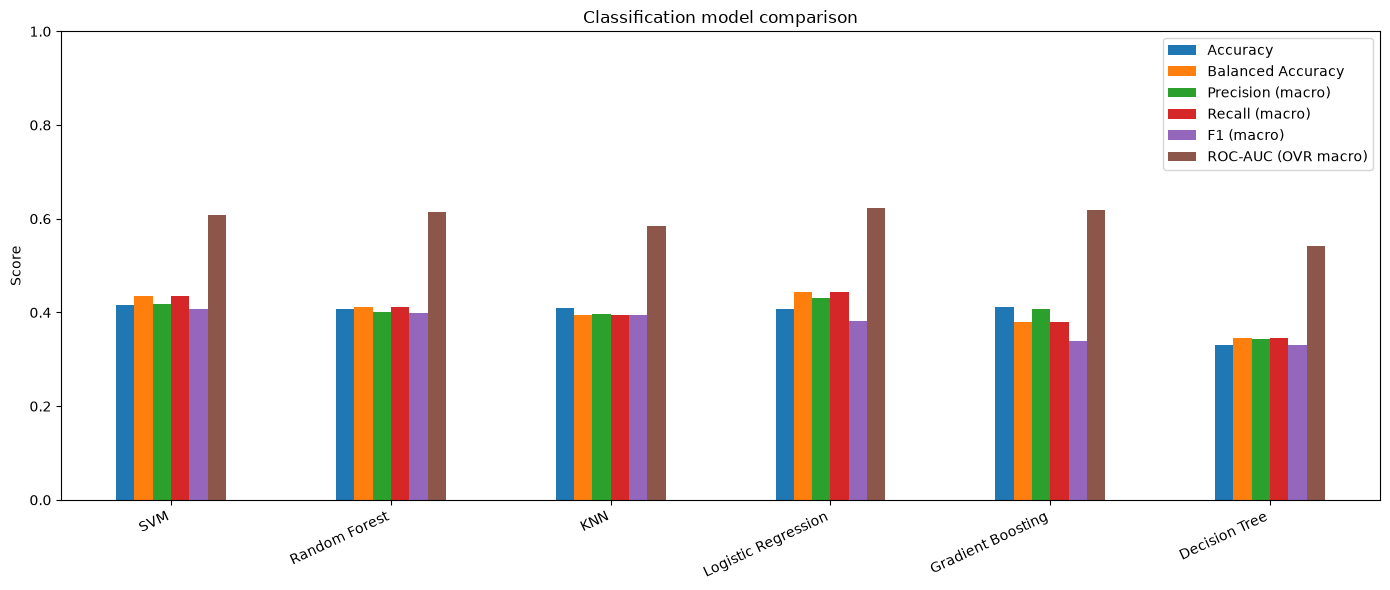

In [8]:
metrics = [
    "Accuracy", "Balanced Accuracy", "Precision (macro)",
    "Recall (macro)", "F1 (macro)", "ROC-AUC (OVR macro)"
]
ax = results_df.set_index("Model")[metrics].plot(
    kind="bar", figsize=(14, 6), ylim=(0, 1)
)
ax.set_title("Classification model comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


Best model by macro F1: SVM
              precision    recall  f1-score   support

         Low       0.38      0.52      0.43       312
      Medium       0.44      0.22      0.30       486
        High       0.44      0.57      0.49       414

    accuracy                           0.42      1212
   macro avg       0.42      0.44      0.41      1212
weighted avg       0.42      0.42      0.40      1212



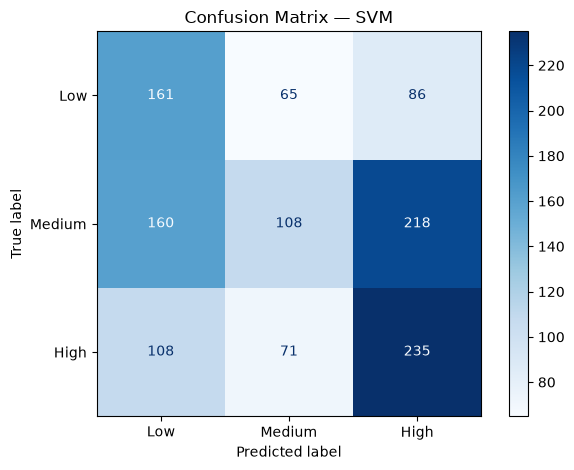

In [9]:
best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

print("Best model by macro F1:", best_model_name)
print(classification_report(
    y_test, best_predictions, labels=CLASS_ORDER, zero_division=0
))

cm = confusion_matrix(y_test, best_predictions, labels=CLASS_ORDER)
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=CLASS_ORDER
).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


In [10]:
RESULTS_DIR = Path("../results")
MODELS_DIR = Path("../models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(RESULTS_DIR / "classification_model_comparison.csv", index=False)

for name, pipeline in trained_models.items():
    safe_name = name.lower().replace(" ", "_")
    joblib.dump(pipeline, MODELS_DIR / f"{safe_name}.joblib")

print("Saved comparison: results/classification_model_comparison.csv")
print("Saved six trained pipelines in models/")


Saved comparison: results/classification_model_comparison.csv
Saved six trained pipelines in models/


In [11]:
# Risk category analysis

risk_analysis = df.groupby("target_risk", observed=False).agg(
    records=("target_risk", "count"),
    avg_incidents_7d=("incidents_sum_7d", "mean"),
    avg_incidents_30d=("incidents_sum_30d", "mean"),
    avg_unusual_activity=("unusual_activity_count", "mean"),
    avg_withdrawals=("withdrawal_count", "mean"),
    avg_future_incidents=("target_incidents_next_7d", "mean")
)

display(risk_analysis.round(2))

,records,avg_incidents_7d,avg_incidents_30d,avg_unusual_activity,avg_withdrawals,avg_future_incidents
target_risk,,,,,,
High,2158,3.21,13.58,2.29,79.51,5.00
Low,1421,2.73,11.94,2.05,80.47,0.72
Medium,2457,2.88,12.51,2.21,80.63,2.47


In [12]:
zone_analysis = df.groupby("zone_id").agg(
    avg_incidents=("cashout_incident_count", "mean"),
    avg_future_incidents=("target_incidents_next_7d", "mean"),
    avg_unusual_activity=("unusual_activity_count", "mean")
)

display(zone_analysis.round(3))

,avg_incidents,avg_future_incidents,avg_unusual_activity
zone_id,,,
ZONE_01,0.302,2.113,1.845
ZONE_02,0.366,2.557,1.720
ZONE_03,0.322,2.237,1.813
ZONE_04,0.491,3.435,1.861
ZONE_05,0.447,3.121,1.728
ZONE_06,0.535,3.759,3.239
ZONE_07,0.451,3.155,3.006
ZONE_08,0.408,2.857,2.290
ZONE_09,0.559,3.932,2.650


In [15]:
from sklearn.feature_selection import mutual_info_classif

X_mi = X_train.copy()

# Convert zone ID to categorical codes
X_mi["zone_id"] = (
    X_mi["zone_id"].astype("category").cat.codes
)

# Explicitly identify categorical columns
categorical_cols = [
    "zone_id",
    "day_of_week",
    "month",
    "is_weekend"
]

discrete_mask = [
    col in categorical_cols for col in X_mi.columns
]

mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

feature_importance = pd.DataFrame({
    "Feature": X_mi.columns,
    "Importance": mi_scores
}).sort_values("Importance", ascending=False)

display(feature_importance.round(5))

,Feature,Importance
0,zone_id,0.04469
2,longitude,0.04170
14,withdrawals_sum_30d,0.03966
1,latitude,0.03921
11,withdrawals_sum_7d,0.02535
13,incidents_sum_7d,0.02202
15,unusual_activity_sum_30d,0.01453
16,incidents_sum_30d,0.01256
19,avg_daily_incidents_30d,0.00926
4,month,0.00889


In [17]:
# Cyclical seasonal feature engineering

start_date = pd.Timestamp("2025-01-01")

day_index = (
    df["date"] - start_date
).dt.days

df["season_30d_sin"] = np.sin(
    2 * np.pi * day_index / 30
)

df["season_30d_cos"] = np.cos(
    2 * np.pi * day_index / 30
)

display(
    df[["date", "season_30d_sin", "season_30d_cos"]].head()
)

,date,season_30d_sin,season_30d_cos
0,2025-01-31,-1.133108e-15,1.0
1,2025-01-31,-1.133108e-15,1.0
2,2025-01-31,-1.133108e-15,1.0
3,2025-01-31,-1.133108e-15,1.0
4,2025-01-31,-1.133108e-15,1.0
